# Gross code：从基本 PPM 到搜索路径与 LER

**[DEMO]** — gross `[[144,12,12]]`，单模块、纯 PPM、电路级 Pauli 噪声。核心构造、编译和导出均由 `lightstim` 提供；本 notebook 只调用与展示。

正式部分共 **5 个代码 cell**：15 个基本测量 → 36 个 shift / 540 个 native measurement → 245 个旋转轴 → 最终搜索路径与操作展开 → **直接执行同一份编译结果**得到 LER。

逻辑编号为 **1–12**，logical qubit 1 用作 pivot 辅助，2–12 存储数据。默认教学目标为 $X_2Z_7X_{12}$，只需一个旋转轴。参考 [Tour de gross](https://arxiv.org/abs/2506.03094) §3.2、附录 A.1–A.5。

下方先导入库并配置参数，不进行搜索或采样。输出统一保存在本 notebook 所在目录的 `assets/bb_ppm/` 中。

服务器运行、安装依赖和续跑方法见 [运行说明](bb_ppm_README.md)。命令行入口 `run_bb_ppm.py` 执行本 notebook；`--reports-only` 只生成前四部分，完整运行才会执行 LER 采样。

In [1]:
from pathlib import Path
from dataclasses import asdict
import contextlib
import hashlib
import importlib.metadata as metadata
import io
import json
import os
import platform
import subprocess
import sys
import time

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "lightstim").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
import stim
from IPython.display import display, Markdown
from IPython.utils.capture import capture_output
import lightstim
from lightstim.protocols.bb_ppm import BBPPMExperiment, BBPPMStep
from lightstim.qec_code.BB_code.ppm.shift import build_tour_de_gross_code, logical_shift_tableaus
from lightstim.qec_code.BB_code.ppm.lowering import BBPPMCompiler
from lightstim.qec_code.BB_code.ppm.native_reporting import export_basic_measurements
from lightstim.qec_code.BB_code.ppm.reporting import (
    format_logical_pauli, export_shift_and_native_catalogs,
    export_rotation_catalog, export_plan_report,
)
from lightstim.noise.config import NoiseConfig
from lightstim.simulation.decoder_backend import SimulationPipeline, DecoderConfig
from lightstim.plot.config import PlotConfig
from lightstim.plot.plotter import plot_custom
from lightstim.plot.utils import add_error_bars

assert Path(lightstim.__file__).resolve().is_relative_to(ROOT)
# The server runner can redirect generated files to a persistent results disk.
OUTPUT = Path(os.environ.get("BB_PPM_OUTPUT_DIR",
    ROOT / "notebooks" / "LogicalOps" / "assets" / "bb_ppm")).expanduser().resolve()
OUTPUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", None)

def display_path(path, *, base=OUTPUT):
    """Format printed paths relative to their stated base directory."""
    return Path(os.path.relpath(Path(path).resolve(), Path(base).resolve())).as_posix()


ROUNDS = 10  # syndrome-extraction rounds per basic LPU measurement
P_VALUES = (1e-3, 2e-3, 3e-3)
MAX_SHOTS, MAX_ERRORS, BATCH_SIZE = 50, 50, 50
NOISE_MODEL = "circuit_level_with_idling"
DECODER_NAME = "relay-bp"
# Paper-aligned gross-code Relay-BP settings in the installed 0.2.2 API.
# Tour de gross Table 7; Relay-BP paper Section IV / Figure 2.
DECODER_PARAMS = {
    "alpha": 1.0, "gamma0": 0.125,
    "pre_iter": 80, "num_sets": 600, "set_max_iter": 60,
    "gamma_dist_interval": (-0.24, 0.66), "stop_nconv": 5,
    "stopping_criterion": "nconv", "parallel": True,
}
REUSE_MATCHING_RESULTS = True  # reuse only identical circuits/settings/software

versions = {name: metadata.version(name) for name in
            ("stim", "numpy", "pandas", "relay-bp", "nbformat", "matplotlib")}
git_base = ["git", "--git-dir", str(ROOT / ".git"), "--work-tree", str(ROOT)]
git_env = dict(os.environ, GIT_OPTIONAL_LOCKS="0")
revision_result = subprocess.run(git_base + ["rev-parse", "HEAD"], cwd=ROOT,
    env=git_env, capture_output=True, text=True)
status_result = subprocess.run(git_base + ["status", "--porcelain"], cwd=ROOT,
    env=git_env, capture_output=True, text=True)
revision = revision_result.stdout.strip() if revision_result.returncode == 0 else None
git_dirty = bool(status_result.stdout.strip()) if status_result.returncode == 0 else None
runtime = {"commit": revision, "git_dirty": git_dirty,
           "python": platform.python_version(),
           "rayon_num_threads": os.environ.get("RAYON_NUM_THREADS", "automatic"), **versions}
print("LightStim:", display_path(lightstim.__file__, base=ROOT))
print("Output folder:", display_path(OUTPUT, base=ROOT))
print("Paths above are relative to the repository; artifact paths below are relative to Output folder.")
display(pd.Series(runtime, name="runtime"))


commit        2926fdf51f9c8920d1bd080f0de81267543609fa
git_dirty                                         True
python                                         3.12.14
stim                                            1.16.0
numpy                                            2.2.6
pandas                                           3.1.1
relay-bp                                         0.2.2
nbformat                                        5.11.1
matplotlib                                      3.11.2
Name: runtime, dtype: object

LightStim: lightstim/__init__.py
Output folder: notebooks/LogicalOps/assets/bb_ppm
Paths above are relative to the repository; artifact paths below are relative to Output folder.


**Cell 1 · 15 个基本 LPU 测量及 stabilizer 定义**

$\mathcal M=\{P_1P_7:P_1,P_7\in\{I,X,Y,Z\}\}\setminus\{I\}$。下表列出全部 15 个。

每种测量保存 JSON 和可读 TXT：目标的物理 Pauli 算符、全部 144 个原 BB 校验及其变形后的形式，以及新增的顶点校验和环校验。算符保留正负号、物理比特编号、数据坐标和边辅助比特标签。

这里的 **144 是列出的 BB 校验数，不是独立校验数**：原 gross code 的 72 个 X 校验和 72 个 Z 校验，在 $\mathrm{GF}(2)$ 上的秩分别为 66 和 66。因此独立 stabilizer 数为 132，编码 $144-132=12$ 个逻辑比特。文件会保存实际计算的秩；这是原 BB code 的计数，不是测量期间整个辅助装置的秩。

这份导出只保存 stabilizer 定义，不包含读出、Bell 电路、gauge-out 反馈或门调度，也不生成电路片段。重新导出时会清理旧 manifest 中登记的本目录电路片段。

检查包括校验两两对易和顶点校验的带符号乘积等于目标。这些代数检查不等同于容错距离认证。

In [2]:
basic_rows = export_basic_measurements(OUTPUT / "basic_measurements", validate=True)
assert len(basic_rows) == 15
display(pd.DataFrame(basic_rows)[[
    "target", "lpu_mode", "vertex_checks", "cycle_checks", "edge_qubits",
    "modified_bb_checks", "validation_status",
]])
print("All 15 stabilizer definitions:", display_path(OUTPUT / "basic_measurements"))
print("All 15 measurement summaries:", display_path(OUTPUT / "basic_measurements" / "manifest.json"))
print("说明：manifest.json 是 15 种测量的汇总目录；具体 stabilizer 定义见各 measurement_*.txt / .json 文件。")


,target,lpu_mode,vertex_checks,cycle_checks,edge_qubits,modified_bb_checks,validation_status
0,X7,right,12,3,18,18,passed
1,Y7,full,23,19,47,36,passed
2,Z7,left,12,5,18,18,passed
3,X1,left,12,5,18,18,passed
4,X1 X7,full,23,19,47,36,passed
5,X1 Y7,full,23,19,47,54,passed
6,X1 Z7,left,12,5,18,36,passed
7,Y1,full,23,19,47,36,passed
8,Y1 X7,full,23,19,47,54,passed
9,Y1 Y7,full,23,19,47,72,passed


All 15 stabilizer definitions: basic_measurements
All 15 measurement summaries: basic_measurements/manifest.json
说明：manifest.json 是 15 种测量的汇总目录；具体 stabilizer 定义见各 measurement_*.txt / .json 文件。


**Cell 2 · 36 个逻辑 shift 与 540 个 native measurement**

36 个 shift 是不同的**逻辑作用**，包含恒等操作。物理 gross 阵列仍是 $12\times6$ 个单元，每个单元有 L/R 两个数据比特；物理位移和逻辑作用的周期分别记录。

对每个基本测量 $P_0$，计算 $N=WP_0W^\dagger$。真正执行测量的时间顺序是 $W^\dagger\rightarrow M(P_0)\rightarrow W$。

显示全部 shift 和 10 个非恒等 shift 扩展示例，完整 540 项保存在文件中，包含符号和来源。

In [2]:
from IPython.display import HTML

gross = build_tour_de_gross_code()
compiler = BBPPMCompiler(logical_shift_tableaus(gross))
catalogs = export_shift_and_native_catalogs(compiler, gross, OUTPUT)
shift_rows = catalogs["rows"]["shifts"]
native_rows = catalogs["rows"]["native_measurements"]
assert len(shift_rows) == 36 and len(native_rows) == 540
display(pd.DataFrame(shift_rows)[[
    "shift", "inverse_shift",
]])
native_table = pd.DataFrame(native_rows)
# Preview genuinely shifted entries; catalogue ordering is by Pauli string.
shifted_preview = native_table[(native_table["shift_x"] != 0) | (native_table["shift_y"] != 0)].head(10)
display(Markdown(f"以下仅展示 {len(shifted_preview)} 个示例，总共有 {len(native_rows)} 个 native measurement。"))
display(HTML(shifted_preview[[
    "basic_measurement", "shift", "conjugated_pauli", "chronology",
]].rename(columns={
    "basic_measurement": "before shift",
    "conjugated_pauli": "after shift",
}).to_html(index=False)))
print("Distinct shifts:", len(shift_rows))
print("Native measurements:", len(native_rows))
for name, path in catalogs["paths"].items():
    print(f"{name}: {display_path(path)}")


,shift,inverse_shift
0,"x: 0, y: 0","x: 0, y: 0"
1,"x: 0, y: 1","x: 0, y: 5"
2,"x: 0, y: 2","x: 0, y: 4"
3,"x: 0, y: 3","x: 0, y: 3"
4,"x: 0, y: 4","x: 0, y: 2"
5,"x: 0, y: 5","x: 0, y: 1"
6,"x: 1, y: 0","x: 5, y: 0"
7,"x: 1, y: 1","x: 5, y: 5"
8,"x: 1, y: 2","x: 5, y: 4"
9,"x: 1, y: 3","x: 5, y: 3"


以下仅展示 10 个示例，总共有 540 个 native measurement。

before shift,shift,after shift,chronology
+X7,"x: 3, y: 5",+X12,"x: 3, y: 1 -> Measure(+X7) -> x: 3, y: 5"
+Z7,"x: 2, y: 4",+Z12,"x: 4, y: 2 -> Measure(+Z7) -> x: 2, y: 4"
+X7,"x: 5, y: 5",+X11,"x: 1, y: 1 -> Measure(+X7) -> x: 5, y: 5"
+X7,"x: 1, y: 5",+X11 X12,"x: 5, y: 1 -> Measure(+X7) -> x: 1, y: 5"
+Z7,"x: 1, y: 2",+Z11,"x: 5, y: 4 -> Measure(+Z7) -> x: 1, y: 2"
+X7,"x: 4, y: 1",+X10,"x: 2, y: 5 -> Measure(+X7) -> x: 4, y: 1"
+X7,"x: 4, y: 0",+X10 X11 X12,"x: 2, y: 0 -> Measure(+X7) -> x: 4, y: 0"
+Z7,"x: 2, y: 5",+Z10,"x: 4, y: 1 -> Measure(+Z7) -> x: 2, y: 5"
+Z7,"x: 5, y: 0",+Z10 Z12,"x: 1, y: 0 -> Measure(+Z7) -> x: 5, y: 0"
+Z7,"x: 0, y: 2",+Z10 Z11,"x: 0, y: 4 -> Measure(+Z7) -> x: 0, y: 2"


Distinct shifts: 36
Native measurements: 540
shifts_json: shifts/shifts.json
shifts_csv: shifts/shifts.csv
native_json: native_measurements/native_measurements.json
native_csv: native_measurements/native_measurements.csv


**Cell 3 · 245 个可实现的非平凡旋转轴 $A$**

从 native measurement 中筛选 $Q_1A$，要求 $Q_1\ne I$ 且 $A\ne I$：得到 **253 个联合测量候选**，按数据部分 $A$ 去重后得到 **245 个旋转轴**。一个轴可能有多种实现，文件保留全部候选以及编译器选中的实现。

每个轴实现 $U_A=e^{+i\pi A/4}$。固定三种循环排列为：准备 Z / 联测 X / 读出 Y；准备 X / 联测 Y / 读出 Z；准备 Y / 联测 Z / 读出 X。结果记为 $r,m,s\in\{\pm1\}$，正向旋转在 $rms=+1$ 时修正 $A$；逆旋转在 $rms=-1$ 时修正 $A$。

In [1]:
rotation_catalog = export_rotation_catalog(compiler, OUTPUT)
axis_rows = rotation_catalog["rows"]["axes"]
implementation_rows = rotation_catalog["rows"]["implementations"]
assert len(axis_rows) == 245 and len(implementation_rows) == 253
axis_preview = pd.DataFrame(axis_rows).head(10)
display(Markdown(f"以下仅展示 {len(axis_preview)} 个示例，总共有 {len(axis_rows)} 个不同的可用旋转轴 A。"))
display(HTML(axis_preview[[
    "axis", "implementation_count", "chosen_joint",
    "chosen_shift", "chosen_basic", "prepare", "readout", "forward_correction",
]].rename(columns={
    "axis": "axis (A)", "chosen_joint": "chosen_joint (Q₁A)",
}).to_html(index=False)))
print("Nontrivial Q1 A implementations:", len(implementation_rows))
print("Distinct nontrivial data rotation axes A:", len(axis_rows))
for name, path in rotation_catalog["paths"].items():
    print(f"{name}: {display_path(path)}")


以下仅展示 10 个示例，总共有 245 个不同的可用旋转轴 A。

axis (A),implementation_count,chosen_joint (Q₁A),chosen_shift,chosen_basic,prepare,readout,forward_correction
+X7,3,+X1 X7,"x: 0, y: 0",+X1 X7,Z1,Y1,r*m*s = +1: apply/track A
+Y7,3,+X1 Y7,"x: 0, y: 0",+X1 Y7,Z1,Y1,r*m*s = +1: apply/track A
+Z7,3,+X1 Z7,"x: 0, y: 0",+X1 Z7,Z1,Y1,r*m*s = +1: apply/track A
+Z6,1,+Z1 Z6,"x: 0, y: 5",+Z1,Y1,X1,r*m*s = +1: apply/track A
+Z6 X8 X11,1,+Z1 Z6 X8 X11,"x: 0, y: 5",+Z1 X7,Y1,X1,r*m*s = +1: apply/track A
+Z6 Z7 Y8 X11,1,+Z1 Z6 Z7 Y8 X11,"x: 0, y: 5",+Z1 Y7,Y1,X1,r*m*s = +1: apply/track A
+Z6 Z7 Z8,1,+Z1 Z6 Z7 Z8,"x: 0, y: 5",+Z1 Z7,Y1,X1,r*m*s = +1: apply/track A
+X4 X6,1,+X1 X4 X6,"x: 5, y: 3",+X1,Z1,Y1,r*m*s = +1: apply/track A
+X4 X6 X7 X8 X10,1,+X1 X4 X6 X7 X8 X10,"x: 5, y: 3",+X1 X7,Z1,Y1,r*m*s = +1: apply/track A
+X4 X6 Y7 X8 Z9 X10 Z11,1,+X1 X4 X6 Y7 X8 Z9 X10 Z11,"x: 5, y: 3",+X1 Y7,Z1,Y1,r*m*s = +1: apply/track A


Nontrivial Q1 A implementations: 253
Distinct nontrivial data rotation axes A: 245
axes_json: rotation_axes/rotation_axes.json
axes_csv: rotation_axes/rotation_axes.csv
implementations_json: rotation_axes/rotation_implementations.json
implementations_csv: rotation_axes/rotation_implementations.csv


**Cell 4 · 双向搜索的扩展过程、选中路径和完整操作展开**

这里定义唯一的输入 `ppm_sequence`，每个元素代表一次联合测量。默认是 $X_2Z_7X_{12}$；可修改为多步序列。

第一个表格记录实际搜索：第 0 轮是初始化，target 端从目标出发，native 端从 245 个可用数据终点出发。节点按忽略整体相位的不同 Pauli 算符去重。每轮选择**待扩展节点较少的一端**扩展一层，并非两端同时或固定交替扩展。

“新增”是本轮新发现的节点数（第 0 轮为初始节点数）；“累计”包含该端已发现的全部节点；“待扩展”是该端下一层的 frontier。计数在完成整层扩展后记录，“连接点”是本轮首先找到、用于重建路径的节点。若复用以前扩展过的 native 端，初始化数量会反映缓存状态；若目标路径已缓存，则注明展示的是原始搜索记录。

随后显示选中的路径。默认例子得到 $X_2Z_7X_{12}\xrightarrow{A=X_2X_7X_{12}}+Y_7$。下面的操作展开按实际时间顺序、按前旋转 / 中央测量 / 逆旋转分组；13 条记录是逻辑指令，不是物理门数。搜索不宣称物理门数、耗时或 LER 最优。

表中的记录、条件与 `output` 表达式使用 **0/1 测量位**：$0\leftrightarrow +1$、$1\leftrightarrow -1$。`XOR` 是测量位的模 2 加法，最终输出本征值为 $(-1)^{\mathrm{output}}$。

默认终点 $Y_7$ 本身可直接测量，所以中央阶段只测 $Y_7$，最终输出为 `ppm0.result`。只有终点不在 native measurement 集合里时，才准备辅助比特并测量 $Q_1R$。旋转内部的联合测量仍在 `pre` / `post` 操作展开中显示。

第 0 轮为初始化；之后每轮扩展待扩展节点较少的一端。新增、累计、待扩展均按不同 Pauli 算符计数。

**PPM 0 — target: +X2 Z7 X12**

搜索轮次,扩展端,target 新增,target 累计,target 待扩展,native 新增,native 累计,native 待扩展,已连接,连接点
0,初始化,1,1,1,245,245,245,否,—
1,target,100,101,100,0,245,245,是,+Y7


,step,rotation,before,axis,direction,after
0,0,0,+X2 Z7 X12,+X2 X7 X12,1,+Y7


以下按执行顺序展开目标 PPM：前置旋转 → 中央测量 → 逆向旋转；右侧大括号标注各阶段。

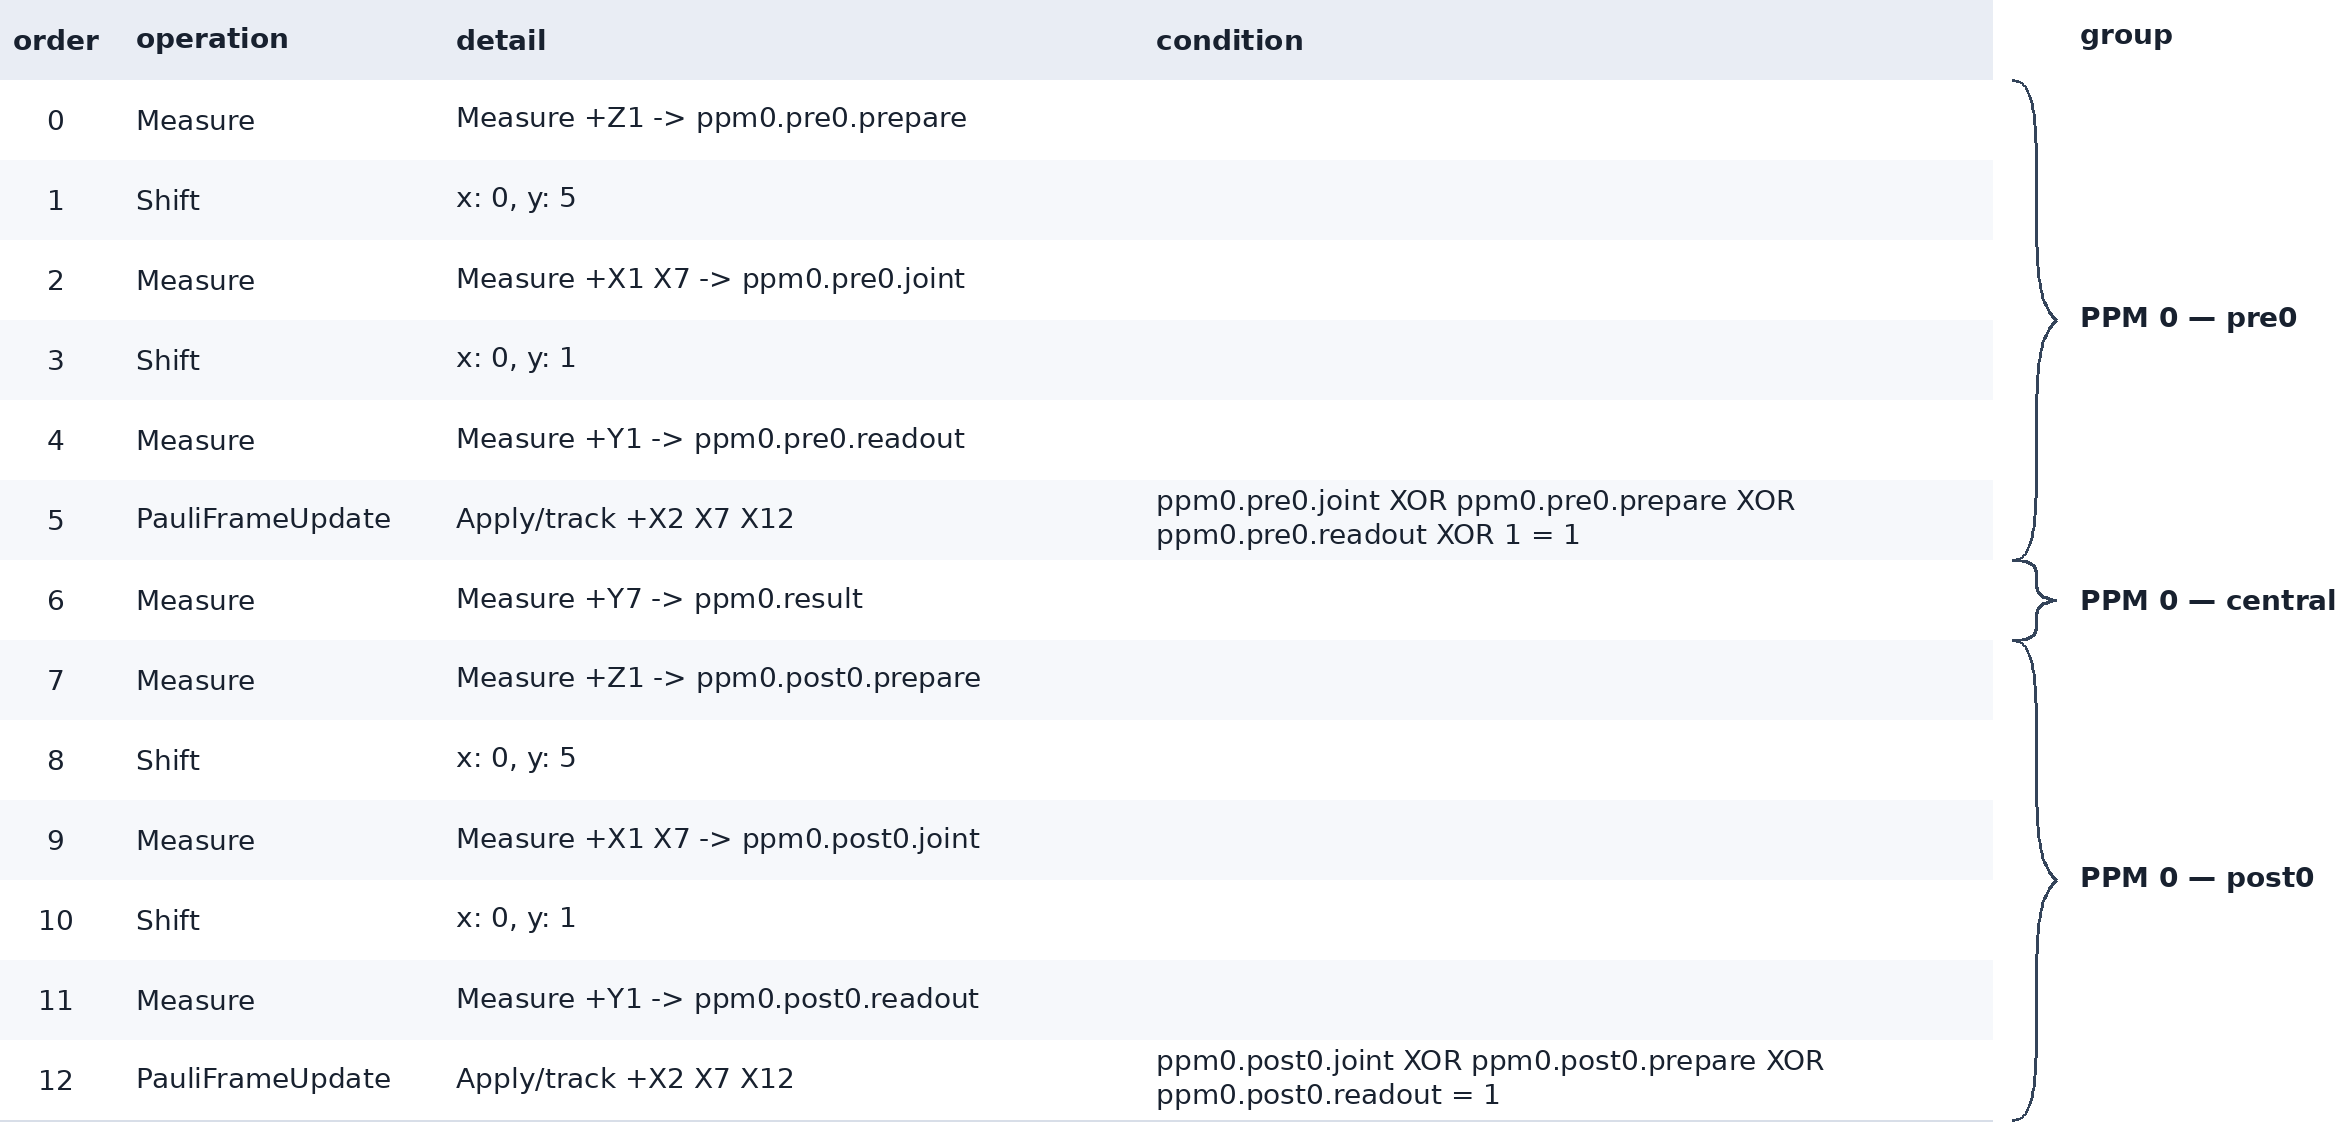

,step,measurements,shifts,frame_updates,output
0,0,7,4,2,ppm0.result


Compiled-plan SHA256: f028b3134db48c3f0f7a6c5b9ae97ddcd7c95cffcb59f8cfc0afc28ad1679a37
plans_json: searches/plans.json
summary_csv: searches/plan_summary.csv
search_csv: searches/search_progress.csv
path_csv: searches/selected_paths.csv
operations_csv: searches/operations.csv


In [1]:
ppm_sequence = [BBPPMStep(((2, "X"), (7, "Z"), (12, "X")))]
# Advanced input example:
# ppm_sequence = [BBPPMStep(((2, "X"), (8, "X"), (9, "X")))]

plans = tuple(compiler.compile(step.targets, prefix=f"ppm{i}")
              for i, step in enumerate(ppm_sequence))
plan_report = export_plan_report(compiler, plans, OUTPUT)
from IPython.display import HTML

display(Markdown("第 0 轮为初始化；之后每轮扩展待扩展节点较少的一端。新增、累计、待扩展均按不同 Pauli 算符计数。"))
for step, plan in enumerate(plans):
    display(Markdown(f"**PPM {step} — target: {format_logical_pauli(plan.target)}**"))
    if plan.search_status == "cached":
        display(Markdown("该目标复用了缓存路径；以下为这条路径首次搜索时的记录，本次没有重新扩展。"))
    search_rows = [row for row in plan_report["rows"]["search"] if row["step"] == step]
    if search_rows:
        search_table = pd.DataFrame(search_rows)[[
            "round", "expanded_side", "target_new", "target_total", "target_frontier",
            "native_new", "native_total", "native_frontier", "connected", "meeting_pauli",
        ]].copy()
        search_table["expanded_side"] = search_table["expanded_side"].map({
            "initial": "初始化", "target": "target", "native": "native"})
        search_table["connected"] = search_table["connected"].map({True: "是", False: "否"})
        search_table["meeting_pauli"] = search_table["meeting_pauli"].fillna("—")
        search_table = search_table.rename(columns={
            "round": "搜索轮次", "expanded_side": "扩展端",
            "target_new": "target 新增", "target_total": "target 累计",
            "target_frontier": "target 待扩展", "native_new": "native 新增",
            "native_total": "native 累计", "native_frontier": "native 待扩展",
            "connected": "已连接", "meeting_pauli": "连接点",
        })
        display(HTML(search_table.to_html(index=False)))
    else:
        display(Markdown("该目标无需双向搜索，直接生成测量方案。"))
path_table = pd.DataFrame(plan_report["rows"]["path"])
if len(path_table):
    display(path_table[["step", "rotation", "before", "axis", "direction", "after"]])
else:
    print("This target needs no Clifford search path.")

from base64 import b64encode
from IPython.display import Image
from lightstim.qec_code.BB_code.ppm.reporting import (
    render_operation_table_png, operation_table_plain_text,
)
display(Markdown("以下按执行顺序展开目标 PPM：前置旋转 → 中央测量 → 逆向旋转；右侧大括号标注各阶段。"))
# Fixed geometry is embedded as PNG so GitHub cannot reflow rows or braces.
operation_rows = plan_report["rows"]["operations"]
operation_png = render_operation_table_png(operation_rows, row_height=40, scale=2)
operation_image = Image(data=operation_png, format="png", retina=True)
display({
    "image/png": b64encode(operation_png).decode("ascii"),
    "text/plain": operation_table_plain_text(operation_rows),
}, raw=True, metadata={"image/png": {
    "width": operation_image.width, "height": operation_image.height,
}})
display(pd.DataFrame(plan_report["rows"]["summary"])[[
    "step", "measurements", "shifts", "frame_updates", "output",
]])
# Search diagnostics do not change the executable measurement plan.
executable_plans = [
    {key: value for key, value in asdict(plan).items()
     if key not in ("search_trace", "search_status")}
    for plan in plans
]
plan_payload = json.dumps(executable_plans, sort_keys=True)
plan_sha256 = hashlib.sha256(plan_payload.encode()).hexdigest()
print("Compiled-plan SHA256:", plan_sha256)
for name, path in plan_report["paths"].items():
    print(f"{name}: {display_path(path)}")


**Cell 5 · 直接执行 Cell 4 的 plans，得到同一 PPM 序列的 LER**

`BBPPMExperiment(..., plans=plans)` 直接使用前一 cell 的对象，不再搜索。先构建并验证无噪物理电路，再交给 LightStim 的 `NoiseConfig`、`SimulationPipeline` 和现有绘图工具。

默认统一 X 初始化/末态读出。$X_2Z_7X_{12}$ 的原始测量结果可以随机为 $\pm1$；失败判据沿用 LightStim 对自动生成 `OBSERVABLE_INCLUDE` 的 decoder 预测检查，不自行定义。这里报告**完整序列实验**的 LER，不是每个基本指令或每轮的 LER。

门、制备、测量和 idle 的噪声参数设为 $p$；初末边界与作为 frame 表示的理想反馈保持无噪。此图是当前调度、内置噪声和 Relay-BP 配置的采样基线，不是论文 Table 2 的精确数值复现。

每个噪声点先采样 50 shots（小样本对照）；误差棒复用 LightStim 的 95% 正态近似。有限样本的 0 次失败保留在结果表中，不在对数轴上伪造正值。增加预算即可提高统计精度。完全匹配编译结果、电路、参数和软件的已有数据会复用；修改输入或配置会生成新的结果目录。

全失败样本在图中仍显示为观测到的 LER=1，但省略已退化的正态近似误差棒；原始工具输出的误差列仍保留在 CSV 中。有限样本全失败并不证明真实失败概率恰好为 1。

解码配置对照 [Tour de gross 附录 A.7 的 Table 7](https://arxiv.org/html/2506.03094v1#A7.T7) 和 [Relay-BP 论文 Section IV / Figure 2](https://arxiv.org/html/2506.01779v1#S4)：当前 API 使用 `num_sets=600`、`pre_iter=80`、`set_max_iter=60`、`stop_nconv=5`、`alpha=1.0`、`gamma0=0.125`、`gamma_dist_interval=(-0.24, 0.66)`。两篇论文的 memory 参数约定不同，这里采用 Relay-BP 论文直接给出的现行约定值；参数对齐不等于整个物理实验精确复现。

自动可观测量检查的是这组初始化与末态读出能够验证的逻辑关联，不是把随机 PPM 输出位本身当作对错标签。

**2026-11-16 服务器运行与论文的对照核查：** 本次在 $p=10^{-3}$ 得到 12/50 次失败（LER=0.24），明显未复现 [论文 Table 2](https://arxiv.org/html/2506.03094v1) 的 gross 原生 in-module measurement 约 $10^{-5}$；表中 $[10^{-11}]$ 对应 two-gross，且方括号表示尚无数据验证的假设值。当前完整序列包含 7 次原生测量和 4 次 shift；序列长度和 50 shots 的统计限制都不足以解释这一巨大差异。

只读核查确认了 Relay-BP 参数与数据传递、理想边界噪声处理，并未发现可解释此差距的明确错误；实际门调度与论文不同，探测器表示的影响尚未通过对照解码确定。**根因仍未定位，不把此图作为论文性能的复现。** 核查没有重新采样或解码，原始计数完整保留。完整核查记录附在已执行 Notebook 的 `bb_ppm_provenance.paper_comparison_audit` 元数据中。

In [ ]:
experiment = BBPPMExperiment(
    gross, ppm_sequence, plans=plans,
    initial_states="X", final_measure_states="X", rounds=ROUNDS,
    rounds_init=1, rounds_final=1, noiseless_boundaries=True,
    noise_model=NOISE_MODEL,
)
assert len(experiment.plans) == len(plans)
assert all(actual is planned for actual, planned in zip(experiment.plans, plans))
started = time.perf_counter()
with capture_output():
    clean = experiment.build()
build_seconds = time.perf_counter() - started
dets, observables = clean.compile_detector_sampler(seed=7).sample(64, separate_observables=True)
assert clean.num_observables > 0 and not dets.any() and not observables.any()
clean.detector_error_model()  # also verifies deterministic detector/observable definitions
circuit_sha256 = hashlib.sha256(str(clean).encode()).hexdigest()
sequence_label = "; ".join(format_logical_pauli(plan.target).lstrip("+") for plan in plans)

source_files = [
    "lightstim/protocols/bb_ppm.py", "lightstim/qec_code/BB_code/ppm/lowering.py",
    "lightstim/qec_code/BB_code/ppm/native.py", "lightstim/qec_code/BB_code/ppm/shift.py",
]
source_hashes = {name: hashlib.sha256((ROOT / name).read_bytes()).hexdigest()
                 for name in source_files}
run_config = {
    "sequence": sequence_label, "targets": [list(step.targets) for step in ppm_sequence],
    "plan_sha256": plan_sha256, "circuit_sha256": circuit_sha256,
    "code": "gross", "logical_basis": "tour_de_gross", "rounds": ROUNDS,
    "initial_states": "X", "final_measure_states": "X", "rounds_init": 1, "rounds_final": 1,
    "noiseless_boundaries": True, "noise_model": NOISE_MODEL,
    "noise_parameters": "p_1q=p_2q=p_meas=p_reset=p_idle=p", "p_values": list(P_VALUES),
    "decoder": DECODER_NAME, "decoder_params": DECODER_PARAMS,
    "max_shots": MAX_SHOTS, "max_errors": MAX_ERRORS, "batch_size": BATCH_SIZE,
    "num_workers": 1, "sampler_seed": 0, "versions": versions,
    "source_sha256": source_hashes, "error_bars": "LightStim 95% normal approximation",
}
run_id = hashlib.sha256(json.dumps(run_config, sort_keys=True).encode()).hexdigest()[:16]
ler_folder = OUTPUT / "ler" / run_id
ler_folder.mkdir(parents=True, exist_ok=True)
config_path, results_path = ler_folder / "configuration.json", ler_folder / "results.csv"
if config_path.exists():
    assert json.loads(config_path.read_text(encoding="utf-8")) == json.loads(json.dumps(run_config))
config_path.write_text(json.dumps(run_config, ensure_ascii=False, indent=2), encoding="utf-8")
(ler_folder / "clean.stim").write_text(str(clean), encoding="utf-8")
resources = {"sequence": sequence_label, "plan_objects_reused": True,
    "physical_qubits": clean.num_qubits, "ticks": clean.num_ticks,
    "detectors": clean.num_detectors, "observables": clean.num_observables,
    "build_seconds": build_seconds, "p0_silent": True,
    "plan_sha256": plan_sha256, "circuit_sha256": circuit_sha256, **runtime}
(ler_folder / "resources.json").write_text(json.dumps(resources, indent=2), encoding="utf-8")
display(pd.Series(resources, name="physical experiment"))
raw = clean.compile_sampler(seed=11).sample(16)
print("Example raw PPM bits (0 -> +1, 1 -> -1; neither value alone means failure):",
      experiment.ppm_outcomes[0].evaluate(raw).astype(int))

all_results = pd.read_csv(results_path) if REUSE_MATCHING_RESULTS and results_path.exists() else pd.DataFrame()
completed_p = set(all_results["p"]) if len(all_results) else set()
pipeline = SimulationPipeline(
    DecoderConfig(DECODER_NAME, params=DECODER_PARAMS),
    max_shots=MAX_SHOTS, max_errors=MAX_ERRORS, batch_size=BATCH_SIZE,
    num_workers=1, print_progress=True,
    progress_min_delta_shots=BATCH_SIZE, progress_interval_sec=60,
    progress_output="logging", progress_file_path=str(ler_folder / "progress.log"),
)
for p in P_VALUES:
    if p in completed_p:
        print(f"p={p:g}: reuse matching sampled result", flush=True)
        continue
    noise = NoiseConfig(p_1q=p, p_2q=p, p_meas=p, p_reset=p, p_idle=p)
    noisy = experiment.builder.build_noisy_circuit(noise, NOISE_MODEL, circuit=clean)
    (ler_folder / f"noisy_p_{p:g}.stim").write_text(str(noisy), encoding="utf-8")
    print(f"p={p:g}: sampling and decoding ...", flush=True)
    point = pipeline.run_batch([(noisy, {
        "p": p, "sequence": sequence_label, "plan_sha256": plan_sha256,
        "run_id": run_id, "max_shots": MAX_SHOTS, "max_errors": MAX_ERRORS,
    })])
    all_results = pd.concat([all_results, point], ignore_index=True)
    checkpoint_path = results_path.with_suffix(".csv.tmp")
    all_results.to_csv(checkpoint_path, index=False)
    checkpoint_path.replace(results_path)  # publish each completed point atomically
    record = point.iloc[0]
    print(f"p={p:g}: {int(record['errors'])}/{int(record['shots'])} failures, "
          f"LER={record['logical_error_rate']:.5g}", flush=True)

all_results = all_results.sort_values("p").reset_index(drop=True)
plot_data = add_error_bars(all_results)
checkpoint_path = results_path.with_suffix(".csv.tmp")
plot_data.to_csv(checkpoint_path, index=False)
checkpoint_path.replace(results_path)
display(plot_data[["sequence", "p", "shots", "errors", "logical_error_rate",
                   "logical_error_rate_err", "seconds"]])
positive = plot_data[plot_data["errors"] > 0]
high_error_range = bool(len(positive)) and positive["logical_error_rate"].min() >= 0.1
if len(positive):
    with capture_output():
        fig = plot_custom(positive, PlotConfig(
            x="p", y="logical_error_rate", hue="sequence",
            palette={sequence_label: "#0072B2"},
            x_label="Physical error rate p", y_label="Logical error rate (whole sequence)",
            title="Gross-code PPM: " + sequence_label + "\nCircuit-level Pauli noise baseline",
            figsize=(8, 5.5), y_scale="linear" if high_error_range else "log",
        ))
    interior = positive[positive["errors"] < positive["shots"]]
    fig.axes[0].errorbar(interior["p"], interior["logical_error_rate"],
        yerr=interior["logical_error_rate_err"], fmt="none", color="#0072B2", capsize=4)
    if high_error_range:
        fig.axes[0].set_ylim(0, 1.05)
else:
    fig, ax = plt.subplots(figsize=(8, 5.5))
    ax.text(0.5, 0.5, "No logical failures observed; increase the sampling budget.", ha="center", transform=ax.transAxes)
    ax.set(xlabel="Physical error rate p", ylabel="Logical error rate (whole sequence)")
if (plot_data["errors"] == plot_data["shots"]).any():
    fig.text(0.5, -0.025, "All-failure samples: normal-approximation error bars omitted.",
             ha="center", fontsize=9)
fig.savefig(ler_folder / "ler.png", dpi=180, bbox_inches="tight")
display(fig)
plt.close(fig)
if (plot_data["errors"] == 0).any():
    print("Zero-error points remain in the table; finite sampling does not establish a zero true LER.")
(OUTPUT / "ler" / "latest.json").write_text(json.dumps({"run_id": run_id,
    "folder": str(ler_folder.resolve()), "plan_sha256": plan_sha256}, indent=2), encoding="utf-8")
print("Sampled results:", display_path(results_path))
print("LER figure:", display_path(ler_folder / "ler.png"))
print("Configuration and physical circuits:", display_path(ler_folder))


本地采样已停止，将在服务器运行。
已完成的本地小样本：p=0.001，50 shots，12 次失败，LER=0.24。
p=0.002 和 p=0.003 尚无完成结果；当前没有完整的三点 LER 图。
以上仅为已保存的本地记录。服务器请按 bb_ppm_README.md 运行，新的结果、图和 executed notebook 将保存在指定输出目录。
